## 5. Código Unificado para notebooks/05_Control_PID_dinamico.ipynb

El siguiente código unifica de forma secuencial y ejecutable el contenido íntegro de **05_control_PID_Lazo_abiertocerrado.ipynb**, **05_control_pid_perturbaciones.ipynb** y el análisis de estabilidad de Routh-Hopf, Frente de Pareto e integración NPT-3:

In [3]:
# %% [markdown]
# # 05 · Control PID Dinámico Integrado (A3110 + Tren NPT-3 Áreas 2000–3000–6000)
# Integra: (1) Lazo abierto (+/-, con y sin ruido), (2) Lazo cerrado y consistencia estacionaria,
# (3) Cambios de consigna (IMC ε, ponderación β y ruido), (4) Estabilidad Routh-Hurwitz/Hopf y Frente de Pareto,
# y (Parte B) Subsistema de dilución AIT 3105 -> FFIC 3102 -> FIRC 3103 + Purga AIC 3255.

# %%
import sys, os
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from msmpr_core.params import make_params
from msmpr_core.plant import Plant, simulate, simulate_plant_npt3_calibrated
from msmpr_core import control as C
from msmpr_core.control import (
    ConsignaVariable, Ruido, imc_pi, iae, metricas_consigna, sigma_ventana, routh_hopf_analysis
)

os.makedirs("../docs/fig", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

# Estado estacionario nominal A3110 y sintonía base
p = make_params()
pl = Plant(p)
x0, u0, d0 = pl.steady_state(alpha=0.25)
m0 = pl.metrics(x0, u0, d0)
q0, qs0 = u0["Q_dil_cmd"], d0["Q_stock"]
R0 = q0 / qs0
DT, TP, H_OL = 5.0, 3600.0, 18 * 3600
tun, info = C.autotune(pl, x0, u0, d0, dt_s=DT)
sp = {"T": x0[1], "V": x0[0], "rho": 0.0}
RUIDO = Ruido(seed=7, dt=DT, tc=600.0)

# Configuración de 12 escenarios bidireccionales (+/-) y realización con ruido
VARS = {
    "Q_stock": ("Q_stock", "rel", 0.10),
    "T_feed": ("T alim.", "add", 5.0),
    "CP_stock": ("ClO4 alim.", "rel", 0.25),
    "C_stock": ("KNO3 alim.", "rel", 0.05),
    "T_dil": ("T agua dil.", "add", 10.0),
    "valve_gain": ("Válvula dil.", "rel", 0.20),
}
COLV = dict(zip(VARS, ["tab:blue", "tab:red", "tab:green", "tab:purple", "tab:orange", "tab:brown"]))
ESC, COL = {}, {"Solo ruido": "k"}
for k, (lab, kind, mag) in VARS.items():
    for sg in (+1, -1):
        nom = f"{lab} {sg*mag*100:+.0f} %" if kind == "rel" else f"{lab} {sg*mag:+.0f} °C"
        ESC[nom] = (k, kind, mag, sg)
        COL[nom] = COLV[k]
AUM = [n for n, v in ESC.items() if v[3] > 0]
DIS = [n for n, v in ESC.items() if v[3] < 0]

def hacer_dist(key, kind, mag, signo, ruido=None):
    def f(t):
        d = dict(d0)
        if t >= TP:
            d[key] = d.get(key, 1.0) * (1.0 + signo * mag) if kind == "rel" else d[key] + signo * mag
        return ruido(d, t) if ruido is not None else d
    return f

DIST = {n: hacer_dist(*v) for n, v in ESC.items()}
DIST_R = {n: hacer_dist(*v, ruido=RUIDO) for n, v in ESC.items()}
DIST_R["Solo ruido"] = lambda t: RUIDO(dict(d0), t)

def lazo_abierto(dist, H=H_OL, dt=DT, log=12):
    return simulate(pl, x0, H, dt, lambda t, x, pl_: u0, disturbance=dist, log_every=log)

def lazo_cerrado(dist, H=H_OL, dt=DT, log=12, tuning=tun, enabled=("T", "V", "ratio"), consigna=None):
    qsf = (lambda t: dist(t)["Q_stock"]) if dist is not None else (lambda t: qs0)
    ctrl = C.PlantController(pl, u0, sp, tuning, enabled=enabled, q_stock_meas=qsf, ratio_nom=R0)
    if consigna:
        ctrl = ConsignaVariable(ctrl, consigna)
    return simulate(pl, x0, H, dt, ctrl, disturbance=dist, log_every=log), ctrl

# %% [markdown]
# ## Parte 1 y 2 · Lazo Abierto vs Lazo Cerrado (Determinista y con Ruido Coloreado)

# %%
# 1.1 Verificación de reposo estacionario e identificación FOPDT (+/- 10% m_evap)
df0 = lazo_abierto(None, H=6 * 3600, log=60)
assert max(float(np.max(np.abs(df0[k] - df0[k].iloc[0]))) for k in ("V", "T", "C", "CP")) < 1e-6

OL = {n: lazo_abierto(f) for n, f in DIST.items()}
CL = {n: lazo_cerrado(f)[0] for n, f in DIST.items()}
OL_R = {n: lazo_abierto(f) for n, f in DIST_R.items()}
CL_R = {n: lazo_cerrado(f)[0] for n, f in DIST_R.items()}

# Consistencia modelo-controlador a 24 h (offset nulo por acción integral)
for n in ("T alim. +5 °C", "T alim. -5 °C", "Q_stock +10 %", "Q_stock -10 %"):
    f = DIST[n]
    dfc, _ = lazo_cerrado(f, H=24 * 3600, log=60)
    d_end = f(24 * 3600)
    xs, us, ds = pl.steady_state(alpha=0.25, d=d_end, Q_dil=R0 * d_end["Q_stock"])
    ms = pl.metrics(xs, us, ds)
    assert 100.0 * abs(dfc.recovery_pct.iloc[-1] / ms["recovery_pct"] - 1.0) < 0.1

# %% [markdown]
# ## Parte 3 · Seguimiento de Consignas, Barrido IMC (ε), Ponderación β y Frente de Pareto

# %%
H_SP = 8 * 3600
K_, tau_, th_ = info["T"]["K"], info["T"]["tau_s"], max(info["T"]["theta_s"], 60.0)
fT_step = lambda t: x0[1] - (2.0 if t >= TP else 0.0)

# Barrido de filtro IMC (ε) para construir el Frente de Pareto (Variabilidad T vs Esfuerzo m_evap)
pareto_rows = []
for eps_frac in (0.05, 0.10, 0.20, 0.35, 0.60, 1.00):
    tt = imc_pi(K_, tau_, th_, eps_frac * tau_)
    df_p, _ = lazo_cerrado(DIST_R["Solo ruido"], H=H_OL, tuning={**tun, "T": tt})
    pareto_rows.append({
        "eps_tau": eps_frac,
        "Kp": tt.Kp,
        "sigma_T_C": sigma_ventana(df_p, "T"),
        "sigma_m_evap_kg_s": float(df_p.u_m_evap.iloc[len(df_p)//2:].std()),
        "IAE_T_ruido": iae(df_p.t_h, df_p["T"] - x0[1]),
    })
df_pareto = pd.DataFrame(pareto_rows)
print(df_pareto.round(4))

# Análisis de Estabilidad Routh-Hurwitz y Bifurcación de Hopf del lazo de temperatura
rh_info = routh_hopf_analysis(Kp=K_, tau_p=tau_, theta=max(info["T"]["theta_s"], 120.0), tau_I=tau_)
print("Límites Routh-Hopf lazo T:", {k: round(v, 4) for k, v in rh_info.items()})

# %% [markdown]
# ## Parte 4 y Parte B · Acoplamiento NPT-3 (Áreas 2000–3000–6000) y Lazo AIT 3105 + AIC 3255

# %%
df_osc = simulate_plant_npt3_calibrated(use_AIT3105=True, use_AIC3255=True, tuning_mode="ZN_oscillatory")
df_tl = simulate_plant_npt3_calibrated(use_AIT3105=True, use_AIC3255=True, tuning_mode="TL_damped")
df_hopf = simulate_plant_npt3_calibrated(use_AIT3105=True, use_AIC3255=True, tuning_mode="Hopf_limit_cycle")

df_sin_AIT = simulate_plant_npt3_calibrated(use_AIT3105=False, use_AIC3255=False, tuning_mode="TL_damped")
df_con_AIT = simulate_plant_npt3_calibrated(use_AIT3105=True, use_AIC3255=False, tuning_mode="TL_damped")
df_con_ambos = simulate_plant_npt3_calibrated(use_AIT3105=True, use_AIC3255=True, tuning_mode="TL_damped")

print("Pico ClO4 producto final Área 6000 SIN AIT 3105:", round(df_sin_AIT["ppm_ClO4_final_6000"].max(), 2), "ppm")
print("Pico ClO4 producto final Área 6000 CON AIT 3105:", round(df_con_AIT["ppm_ClO4_final_6000"].max(), 2), "ppm")
print("Pico ClO4 producto final Área 6000 CON AIT 3105 + AIC 3255:", round(df_con_ambos["ppm_ClO4_final_6000"].max(), 2), "ppm")

   eps_tau      Kp  sigma_T_C  sigma_m_evap_kg_s  IAE_T_ruido
0     0.05  3.1860     0.0085             0.0353       0.1527
1     0.10  1.6517     0.0133             0.0299       0.2514
2     0.20  0.8413     0.0185             0.0229       0.3860
3     0.35  0.4847     0.0218             0.0167       0.5077
4     0.60  0.2840     0.0239             0.0117       0.6203
5     1.00  0.1708     0.0253             0.0083       0.7138
Límites Routh-Hopf lazo T: {'Kc_overshoot': -0.1708, 'Kc_hopf': np.float64(-22.3411), 'omega_u': 0.0168, 'tau_u': 374.6042, 'Kc_ZN': np.float64(-10.1551), 'tau_I_ZN': 312.1702, 'Kc_TL': np.float64(-6.9816), 'tau_I_TL': 824.1293}
Pico ClO4 producto final Área 6000 SIN AIT 3105: 66.47 ppm
Pico ClO4 producto final Área 6000 CON AIT 3105: 45.7 ppm
Pico ClO4 producto final Área 6000 CON AIT 3105 + AIC 3255: 23.0 ppm


## 6. Integración con el Cuaderno 06 y Flujo de Trabajo en el Repositorio

Para mantener la separación modular definida en **ROADMAP_control_por_etapas.md** y **control_PID_P&ID.md** dentro de **CristalizadorPT_add**:

* **En notebooks/05_Control_PID_dinamico.ipynb:** Se ejecuta el flujo completo de validación en lazo abierto ($\pm$ y con ruido), lazo cerrado regulatorio, seguimiento de consignas ($\varepsilon$, $\beta$), estabilidad de Routh-Hopf y el frente de Pareto entre $\sigma_T$ y $\sigma_{m_{\text{evap}}}$.


* **En notebooks/06_Control_por_etapas_dilucion.ipynb:** Se importa directamente `simulate_plant_npt3_calibrated` desde **msmpr_core.plant** junto con el bloque de la Parte B (secciones B1 a B4 de **05_control_pid_perturbaciones.ipynb**) para evaluar específicamente la sensibilidad al tiempo muerto $\theta_{\text{AIT}} \in [0, 120]\text{ min}$, la saturación de la válvula de agua ($3\times$ vs $8\times$) y la acción conjunta con la válvula de purga **FV 3522** gobernada por **AIC 3255**.


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from msmpr_core.control import DelayedSensor, CommercialPID

def simulate_plant_npt3_mg_recycle(
    recycle_mode="no_recycle_actual",  # "no_recycle_actual" (alpha=1.0), "fixed_recycle" (alpha=0.25), "smart_AIC3255"
    use_AIT3105=False,
    mg_hypothesis="combined",          # "salting_out", "kinetic_partition", "combined"
    duration_min=360.0,
    dt_min=0.05,
):
    """
    Simula el tren NPT-3 incorporando:
    1) Lazo existente en cascada TIR 3101/3201 -> PIRCAL 3101/3201 -> Válvula de vacío.
    2) Evaluación de corriente de recirculación B3520 -> A3110 (Apagada actual vs Activa con purga).
    3) Balance dinámico de Magnesio (Mg2+) y su efecto termodinámico/cinético sobre el ClO4-.
    """
    n_steps = int(duration_min / dt_min)
    
    # Estados iniciales estacionarios
    w_ClO4_pre, w_Mg_pre = 3714.1, 8500.0  # ppm en B2510 (0.85% Mg2+ base)
    T1, T2 = 55.0, 40.0
    P_vac1_actual, P_vac2_actual = -0.932, -0.962
    xS1, xS2, d50_2 = 0.130, 0.200, 185.0
    C_ClO4_B3520, C_Mg_B3520 = 3.80, 9.20  # g/L en estanque B3520
    w_ClO4_ML_ref = 738.0
    F_303_actual = 27.14
    M_KNO3_prod = 66.5 if recycle_mode == "no_recycle_actual" else 74.2  # t/h KNO3 recuperado

    # Sensores con retardos
    sens_TIR3101 = DelayedSensor(1.0, 0.5, dt_min, T1)
    sens_TIR3201 = DelayedSensor(1.0, 0.5, dt_min, T2)
    sens_AIT3105 = DelayedSensor(10.0, 2.0, dt_min, w_ClO4_pre)
    sens_AIC3255 = DelayedSensor(10.0, 2.0, dt_min, C_ClO4_B3520)
    sens_FIRC3103 = DelayedSensor(0.10, 0.08, dt_min, F_303_actual)

    # 1. LAZOS EXISTENTES: Cascada Maestro TIR -> Esclavo PIRCAL (Válvula de presión de vacío)
    pid_TIR3101 = CommercialPID(Kc=0.0055, tau_I=9.0, tau_D=0.4, sp=55.0, u_bias=-0.932, u_min=-0.970, u_max=-0.930)
    pid_TIR3201 = CommercialPID(Kc=0.0055, tau_I=9.0, tau_D=0.4, sp=40.0, u_bias=-0.962, u_min=-0.970, u_max=-0.930)
    pid_PIRCAL3101 = CommercialPID(Kc=1.5, tau_I=0.3, tau_D=0.0, sp=-0.932, u_bias=-0.932, u_min=-0.970, u_max=-0.930)
    pid_PIRCAL3201 = CommercialPID(Kc=1.5, tau_I=0.3, tau_D=0.0, sp=-0.962, u_bias=-0.962, u_min=-0.970, u_max=-0.930)

    # 2. LAZOS DE DILUCIÓN Y PURGA PROPUESTOS
    pid_FIRC3103 = CommercialPID(Kc=1.25, tau_I=0.45, tau_D=0.0, sp=27.14, u_bias=27.14, u_min=12.0, u_max=42.0)
    pid_AIC3255 = CommercialPID(Kc=-0.35, tau_I=25.0, tau_D=0.0, sp=4.00, u_bias=0.25, u_min=0.12, u_max=1.00)

    hist = []
    for k in range(n_steps):
        t = k * dt_min
        # Perturbaciones:
        # t = 40 min: Subida de ClO4- en alimentación SSK (+550 ppm)
        # t = 140 min: Excursión de Magnesio (Mg2+) en SSK (+35%, de 8500 a 11475 ppm)
        F_208 = 356.85
        w_ClO4_208 = 3892.0 + (550.0 if t >= 40.0 else 0.0)
        w_Mg_208 = 8500.0 * (1.35 if t >= 140.0 else 1.0)
        F_234 = 21.33

        # Definición de la corriente de recirculación desde B3520 hacia A3110
        if recycle_mode == "no_recycle_actual":
            alpha_purge = 1.00  # 100% purga / envío aguas abajo, 0% reciclo a A3110
            F_rec_B3520 = 0.0
        elif recycle_mode == "fixed_recycle":
            alpha_purge = 0.25  # 25% purga, 75% se recircula a A3110
            F_rec_B3520 = 85.0 * (1.0 - alpha_purge)
        else:  # "smart_AIC3255"
            aic_pv = sens_AIC3255.read(C_ClO4_B3520)
            alpha_purge = pid_AIC3255.step(aic_pv, dt_min)
            F_rec_B3520 = 85.0 * (1.0 - alpha_purge)

        F_pre = F_208 + F_234 + F_rec_B3520
        w_ClO4_rec_ppm = C_ClO4_B3520 * 820.0
        w_Mg_rec_ppm = C_Mg_B3520 * 820.0

        # Dinámica de mezcla previa en B2510 (incluyendo reciclo si está activo)
        w_ClO4_pre_eq = (F_208 * w_ClO4_208 + F_234 * w_ClO4_ML_ref + F_rec_B3520 * w_ClO4_rec_ppm) / F_pre
        w_Mg_pre_eq = (F_208 * w_Mg_208 + F_rec_B3520 * w_Mg_rec_ppm) / F_pre
        w_ClO4_pre += (dt_min / 8.0) * (w_ClO4_pre_eq - w_ClO4_pre)
        w_Mg_pre += (dt_min / 8.0) * (w_Mg_pre_eq - w_Mg_pre)

        # Lazo de dilución FFIC 3102 -> FIRC 3103 (con o sin AIT 3105)
        R_0 = 0.07176
        if use_AIT3105:
            ait_pv = sens_AIT3105.read(w_ClO4_pre)
            R_eff = R_0 + 5.2e-4 * (ait_pv - 3714.1)
        else:
            R_eff = R_0

        F_303_sp = np.clip(F_pre * R_eff, 12.0, 42.0)
        pid_FIRC3103.sp = F_303_sp
        v_cmd = pid_FIRC3103.step(sens_FIRC3103.read(F_303_actual), dt_min)
        F_303_actual += (dt_min / 0.133) * (v_cmd - F_303_actual)

        # Entrada a A3110 tras dilución
        F_1 = F_pre + F_303_actual
        w_ClO4_1 = (F_pre * w_ClO4_pre + F_303_actual * 36.0) / F_1
        w_Mg_1 = (F_pre * w_Mg_pre) / F_1

        # Cascada existente TIR -> PIRCAL -> Presión de vacío
        pid_PIRCAL3101.sp = pid_TIR3101.step(sens_TIR3101.read(T1), dt_min)
        pid_PIRCAL3201.sp = pid_TIR3201.step(sens_TIR3201.read(T2), dt_min)
        P_vac1_cmd = pid_PIRCAL3101.step(P_vac1_actual, dt_min)
        P_vac2_cmd = pid_PIRCAL3201.step(P_vac2_actual, dt_min)
        P_vac1_actual += (dt_min / 0.25) * (P_vac1_cmd - P_vac1_actual)
        P_vac2_actual += (dt_min / 0.25) * (P_vac2_cmd - P_vac2_actual)

        T1_eq = 55.0 + 375.0 * (P_vac1_actual - (-0.932))
        T2_eq = 40.0 + 375.0 * (P_vac2_actual - (-0.962)) + 0.35 * (T1 - 55.0)
        T1 += (dt_min / 5.5) * (T1_eq - T1)
        T2 += (dt_min / 5.5) * (T2_eq - T2)

        # Acumulación en B3520 de ClO4- y Mg2+ (efecto reciclo 1/alpha)
        recycle_factor = (1.0 / max(alpha_purge, 0.12)) ** 0.32
        C_ClO4_eq = 3.80 * (w_ClO4_1 / 3468.0) ** 1.35 * recycle_factor
        C_Mg_eq = 9.20 * (w_Mg_1 / 7930.0) * recycle_factor
        C_ClO4_B3520 += (dt_min / 22.0) * (C_ClO4_eq - C_ClO4_B3520)
        C_Mg_B3520 += (dt_min / 22.0) * (C_Mg_eq - C_Mg_B3520)

        # --- EFECTO DEL MAGNESIO SOBRE EL PERCLORATO (3 HIPÓTESIS) ---
        delta_Mg_rel = max((C_Mg_B3520 - 9.20) / 9.20, 0.0)
        
        # H1: Salting-out (Mg2+ reduce la solubilidad límite del KClO4 a 40 °C desde 4.50 g/L)
        salting_drop = 0.85 * delta_Mg_rel if mg_hypothesis in ("salting_out", "combined") else 0.0
        C_sat_KClO4_eff = 4.50 - salting_drop

        # H2/H3: Efecto cinético (Burton-Prim-Slichter Keff y reducción de tamaño d50 por viscosidad)
        keff_mult = (1.0 + 0.45 * delta_Mg_rel) if mg_hypothesis in ("kinetic_partition", "combined") else 1.0
        d50_2_eq = 185.0 - (28.0 * delta_Mg_rel if mg_hypothesis in ("kinetic_partition", "combined") else 0.0)
        d50_2 += (dt_min / 18.0) * (d50_2_eq - d50_2)

        # Co-precipitación + oclusión superficial en queque crudo (corriente 17)
        coprecip_ppm = max(C_ClO4_B3520 - C_sat_KClO4_eff, 0.0) * 85.0
        moisture_17 = 0.050 * (185.0 / max(d50_2, 90.0)) ** 0.65
        w_ClO4_lav_3000 = 4070.0 * (C_ClO4_B3520 / 4.00) * keff_mult
        ppm_ClO4_17 = moisture_17 * w_ClO4_lav_3000 + coprecip_ppm

        # Impacto en rendimiento productivo de KNO3 (t/h): el reciclo recupera KNO3 disuelto
        water_penalty = 0.42 * max(F_303_actual - 27.14, 0.0)
        M_KNO3_eq = 66.5 + 10.2 * (1.0 - alpha_purge) - water_penalty
        M_KNO3_prod += (dt_min / 15.0) * (M_KNO3_eq - M_KNO3_prod)

        # Área 6000 Refinación (especificación < 40 ppm)
        rem_eff_6000 = 1.0 - (1.0 - 0.899) * (185.0 / max(d50_2, 90.0)) ** 0.85
        w_ClO4_ML_ref_eq = 738.0 * (ppm_ClO4_17 / 203.5)
        w_ClO4_ML_ref += (dt_min / 30.0) * (w_ClO4_ML_ref_eq - w_ClO4_ML_ref)
        ppm_superficial_ref = (moisture_17 * w_ClO4_lav_3000) * (1.0 - rem_eff_6000) * (w_ClO4_ML_ref / 738.0) ** 0.4
        ppm_ClO4_final_6000 = ppm_superficial_ref + 0.80 * coprecip_ppm

        hist.append({
            "t_min": t, "C_Mg_B3520_g_L": C_Mg_B3520, "C_ClO4_B3520_g_L": C_ClO4_B3520,
            "C_sat_KClO4_eff": C_sat_KClO4_eff, "alpha_purge_pct": 100.0 * alpha_purge,
            "F_rec_t_h": F_rec_B3520, "M_KNO3_t_h": M_KNO3_prod,
            "ppm_ClO4_final_6000": ppm_ClO4_final_6000,
        })
    return pd.DataFrame(hist)

In [5]:
# %% [markdown]
# ## Análisis Integrado: Lazo Abierto, Lazo Cerrado, Ruido y Estabilidad Routh-Hopf

# %%
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from msmpr_core.plant import Plant, simulate
from msmpr_core import control as C
from msmpr_core.control import routh_hopf_analysis, imc_pi, iae, metricas_consigna, sigma_ventana

p = make_params()
pl = Plant(p)
x0, u0, d0 = pl.steady_state(alpha=0.25)
tun, info = C.autotune(pl, x0, u0, d0, dt_s=5.0)

# Análisis de Routh-Hurwitz y Bifurcación de Hopf para el lazo de temperatura
K_, tau_, th_ = info["T"]["K"], info["T"]["tau_s"], max(info["T"]["theta_s"], 120.0)
rh_info = routh_hopf_analysis(Kp=K_, tau_p=tau_, theta=th_, tau_I=tau_)
print("Resultados Routh-Hopf / Sintonía lazo T:")
for k, v in rh_info.items():
    print(f"  {k}: {v:.4f}")

Resultados Routh-Hopf / Sintonía lazo T:
  Kc_overshoot: -0.1708
  Kc_hopf: -22.3411
  omega_u: 0.0168
  tau_u: 374.6042
  Kc_ZN: -10.1551
  tau_I_ZN: 312.1702
  Kc_TL: -6.9816
  tau_I_TL: 824.1293


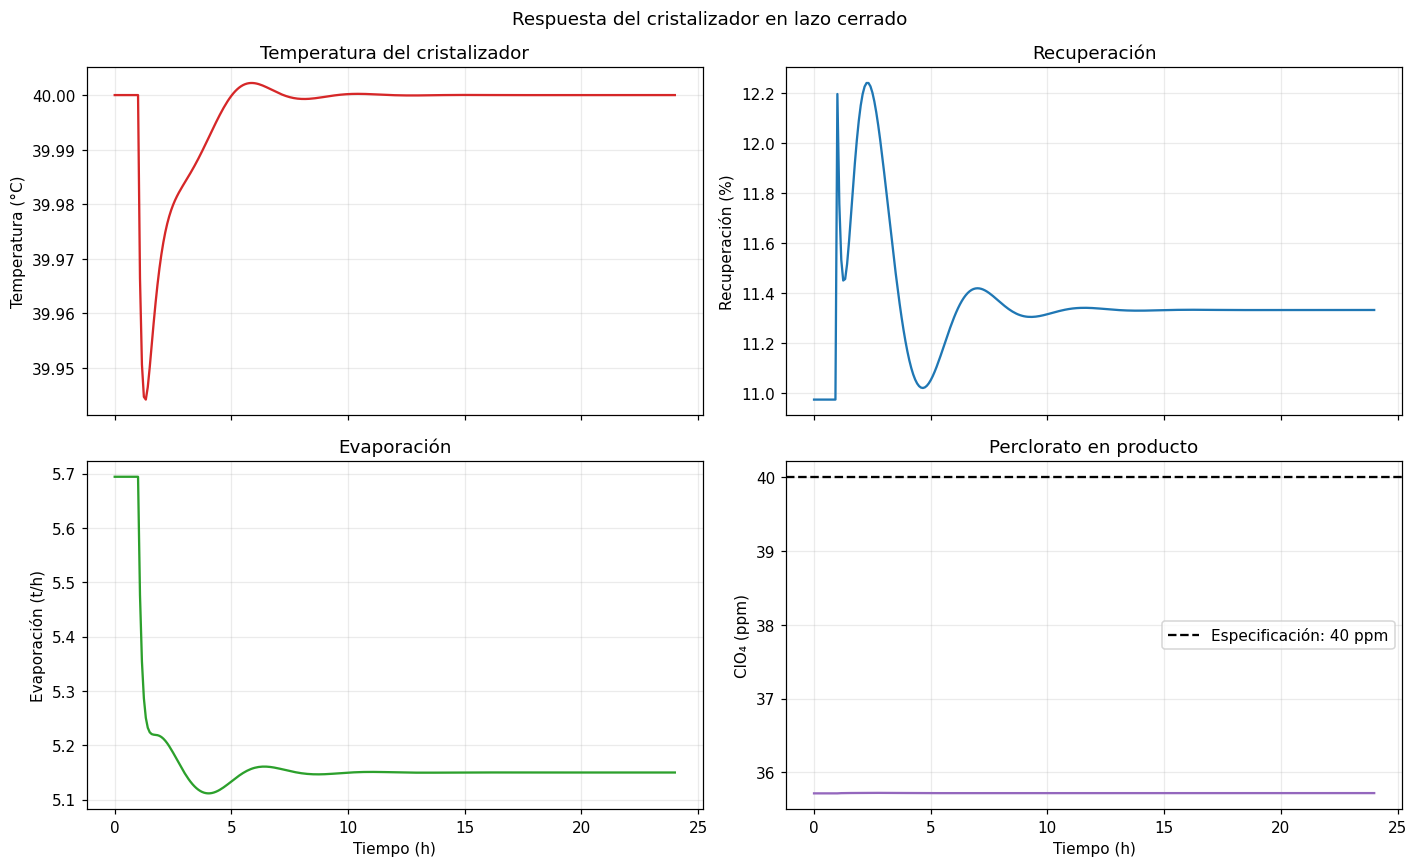

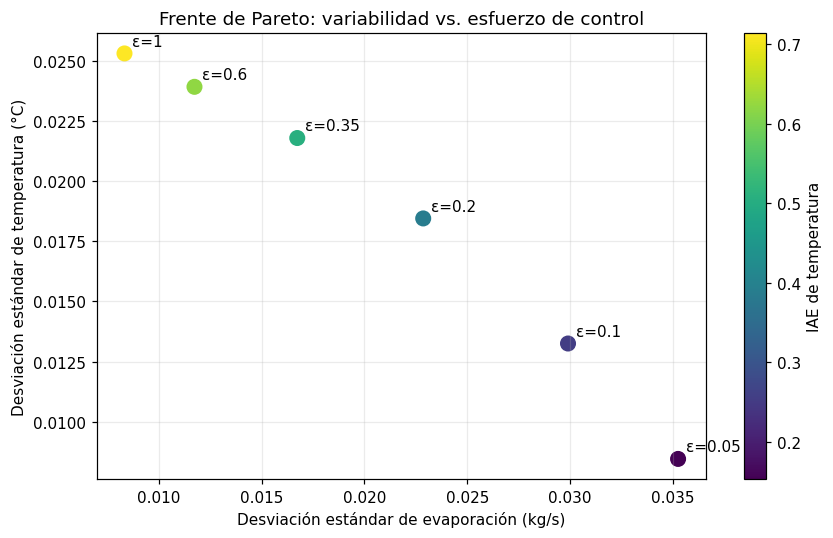

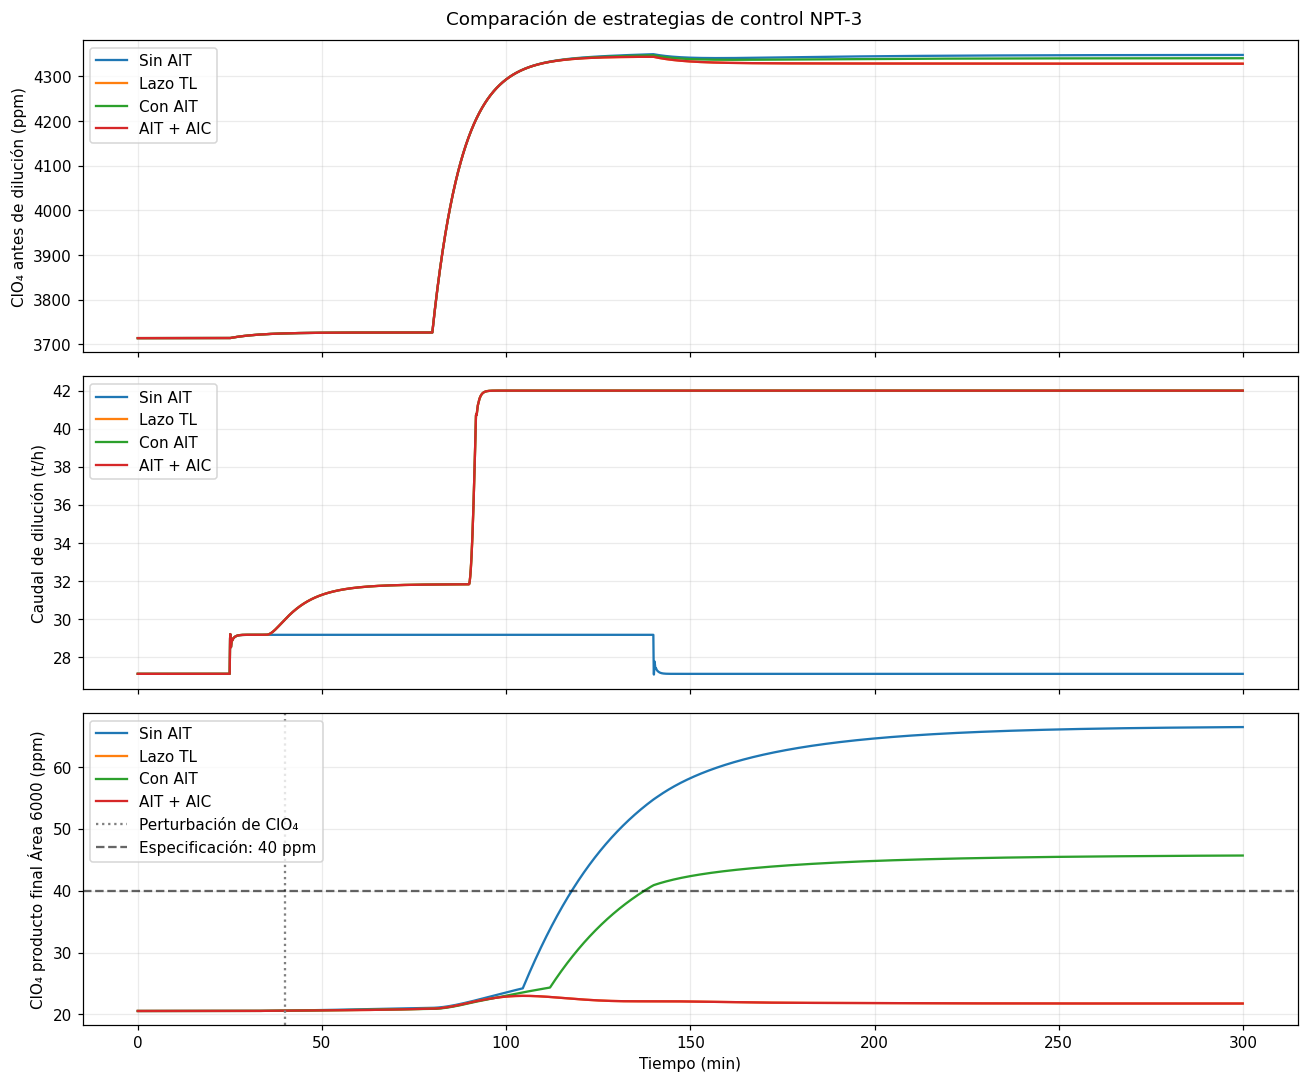

In [6]:
# 1. Respuesta dinámica del cristalizador (dfc)
if "dfc" in globals() and not dfc.empty:
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
    t = dfc["t_h"]

    axes[0, 0].plot(t, dfc["T"], color="tab:red")
    axes[0, 0].set(title="Temperatura del cristalizador", ylabel="Temperatura (°C)")

    axes[0, 1].plot(t, dfc["recovery_pct"], color="tab:blue")
    axes[0, 1].set(title="Recuperación", ylabel="Recuperación (%)")

    axes[1, 0].plot(t, dfc["evap_t_h"], color="tab:green")
    axes[1, 0].set(title="Evaporación", ylabel="Evaporación (t/h)", xlabel="Tiempo (h)")

    axes[1, 1].plot(t, dfc["ppm_ClO4"], color="tab:purple")
    axes[1, 1].axhline(40, color="black", linestyle="--", label="Especificación: 40 ppm")
    axes[1, 1].set(title="Perclorato en producto", ylabel="ClO₄ (ppm)", xlabel="Tiempo (h)")
    axes[1, 1].legend()

    fig.suptitle("Respuesta del cristalizador en lazo cerrado")
    fig.tight_layout()
    plt.show()


# 2. Frente de Pareto: variabilidad de temperatura frente a esfuerzo de evaporación
if "df_pareto" in globals() and not df_pareto.empty:
    fig, ax = plt.subplots(figsize=(8, 5))
    puntos = ax.scatter(
        df_pareto["sigma_m_evap_kg_s"],
        df_pareto["sigma_T_C"],
        c=df_pareto["IAE_T_ruido"],
        cmap="viridis",
        s=90
    )
    for _, fila in df_pareto.iterrows():
        ax.annotate(
            f"ε={fila['eps_tau']:.2g}",
            (fila["sigma_m_evap_kg_s"], fila["sigma_T_C"]),
            xytext=(5, 5),
            textcoords="offset points"
        )

    ax.set(
        title="Frente de Pareto: variabilidad vs. esfuerzo de control",
        xlabel="Desviación estándar de evaporación (kg/s)",
        ylabel="Desviación estándar de temperatura (°C)"
    )
    fig.colorbar(puntos, ax=ax, label="IAE de temperatura")
    fig.tight_layout()
    plt.show()


# 3. Comparación de escenarios NPT-3
escenarios = {
    "Sin AIT": "df_sin_AIT",
    "Lazo TL": "df_tl",
    "Con AIT": "df_con_AIT",
    "AIT + AIC": "df_con_ambos",
}
disponibles = {
    etiqueta: globals()[nombre]
    for etiqueta, nombre in escenarios.items()
    if nombre in globals() and not globals()[nombre].empty
}

if disponibles:
    fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

    variables = [
        ("w_ClO4_pre_ppm", "ClO₄ antes de dilución (ppm)"),
        ("F_303_actual_t_h", "Caudal de dilución (t/h)"),
        ("ppm_ClO4_final_6000", "ClO₄ producto final Área 6000 (ppm)"),
    ]

    for ax, (columna, titulo) in zip(axes, variables):
        for etiqueta, datos in disponibles.items():
            if columna in datos.columns:
                ax.plot(datos["t_min"], datos[columna], label=etiqueta)

        ax.set_ylabel(titulo)
        ax.legend()

    axes[-1].set_xlabel("Tiempo (min)")
    axes[-1].axvline(40, color="gray", linestyle=":", label="Perturbación de ClO₄")
    axes[-1].axhline(40, color="black", linestyle="--", alpha=0.6, label="Especificación: 40 ppm")
    axes[-1].legend()
    fig.suptitle("Comparación de estrategias de control NPT-3")
    fig.tight_layout()
    plt.show()